In [1]:
import os
import hashlib
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from PIL import Image

# Auto-detect the dataset folder that contains Training and Testing
BASE = None
for root, dirs, files in os.walk("/kaggle/input"):
    if "Training" in dirs and "Testing" in dirs:
        BASE = root
        break

print("Dataset path:", BASE)
assert BASE is not None, "Dataset not found. Add it first using '+ Add Input' in the right panel."

# Fix random seed for reproducible sampling
random.seed(42)
np.random.seed(42)
sns.set_style("whitegrid")

Dataset path: /kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset


First, verify that the dataset is mounted correctly, see which folders exist, and how many files each folder holds. This is the foundation for all later steps.

In [2]:
# Show top-level content of the dataset folder
print("Top-level content:", os.listdir(BASE))

# Walk through the folders and count files in each
for root, dirs, files in os.walk(BASE):
    if files:
        print(f"{root} -> {len(files)} files")

Top-level content: ['Training', 'Testing']
/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Training/pituitary -> 1400 files
/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Training/notumor -> 1400 files
/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Training/meningioma -> 1400 files
/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Training/glioma -> 1400 files
/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Testing/pituitary -> 400 files
/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Testing/notumor -> 400 files
/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Testing/meningioma -> 400 files
/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Testing/glioma -> 400 files


We build a DataFrame (df) holding the path, split, class, file format and file size of every image. This df is reused in all later steps.

In [3]:
records = []
for split in ["Training", "Testing"]:
    split_dir = os.path.join(BASE, split)
    for cls in sorted(os.listdir(split_dir)):
        cls_dir = os.path.join(split_dir, cls)
        if not os.path.isdir(cls_dir):
            continue
        for fname in os.listdir(cls_dir):
            fpath = os.path.join(cls_dir, fname)
            records.append({
                "path": fpath,
                "split": split,
                "label": cls,
                "ext": os.path.splitext(fname)[1].lower(),
                "size_kb": os.path.getsize(fpath) / 1024
            })

df = pd.DataFrame(records)

print("Total images:", len(df))
print("Classes:", sorted(df["label"].unique()))
print("\nImages per split:\n", df["split"].value_counts())
print("\nFile formats:\n", df["ext"].value_counts())
print("\nFile size (KB) summary:\n", df["size_kb"].describe())

Total images: 7200
Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']

Images per split:
 split
Training    5600
Testing     1600
Name: count, dtype: int64

File formats:
 ext
.jpg    7200
Name: count, dtype: int64

File size (KB) summary:
 count    7200.000000
mean       22.765972
std        15.918904
min         3.594727
25%        15.735840
50%        21.196777
75%        26.750244
max       299.308594
Name: size_kb, dtype: float64


We count images per class and plot a bar chart to check whether the dataset is balanced or imbalanced. With imbalance, a model tends to favor the majority class.

label     glioma  meningioma  notumor  pituitary
split                                           
Testing      400         400      400        400
Training    1400        1400     1400       1400


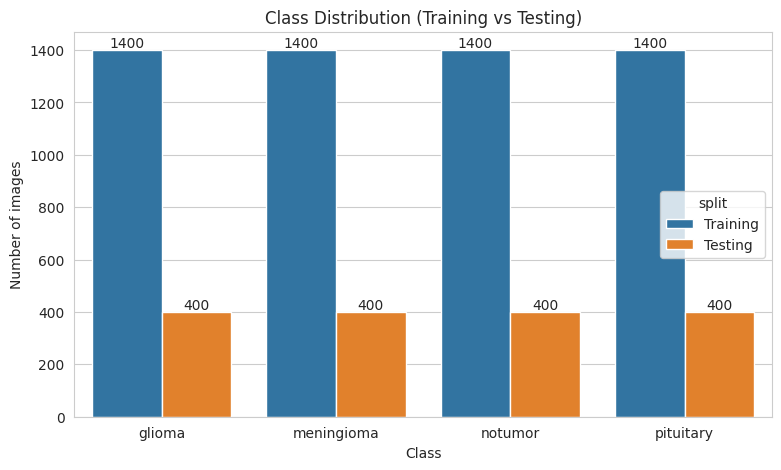


Imbalance ratio (max/min) in Training: 1.0


In [4]:
# Count table
class_counts = df.groupby(["split", "label"]).size().unstack(fill_value=0)
print(class_counts)

# Bar chart: class distribution for each split
plt.figure(figsize=(9, 5))
ax = sns.countplot(data=df, x="label", hue="split")
for container in ax.containers:
    ax.bar_label(container)
plt.title("Class Distribution (Training vs Testing)")
plt.xlabel("Class")
plt.ylabel("Number of images")
plt.show()

# Imbalance ratio in the training set
train_counts = df[df["split"] == "Training"]["label"].value_counts()
print("\nImbalance ratio (max/min) in Training:",
      round(train_counts.max() / train_counts.min(), 2))

We extract width, height and color mode (L = grayscale, RGB = 3 channels) of every image. If sizes differ, we must resize before feeding a model. Image.open() reads only the header, so this is fast.

Color modes:
 mode
RGB     4129
L       3067
RGBA       3
P          1
Name: count, dtype: int64

Number of unique image sizes: 447

Top 10 most common sizes:
width  height
512    512       5014
225    225        338
630    630         90
201    251         57
228    221         51
232    217         50
236    236         48
442    442         48
150    198         44
200    252         43
dtype: int64


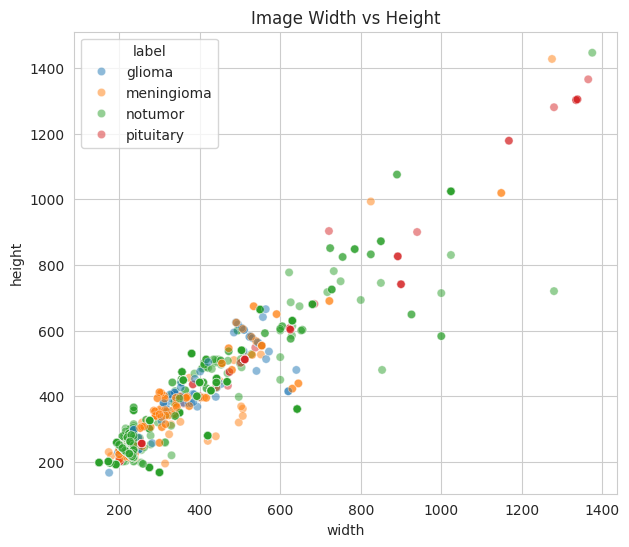

In [5]:
widths, heights, modes = [], [], []
for p in df["path"]:
    with Image.open(p) as im:
        widths.append(im.size[0])
        heights.append(im.size[1])
        modes.append(im.mode)

df["width"] = widths
df["height"] = heights
df["mode"] = modes

print("Color modes:\n", df["mode"].value_counts())
print("\nNumber of unique image sizes:", df.groupby(["width", "height"]).ngroups)
print("\nTop 10 most common sizes:")
print(df.groupby(["width", "height"]).size().sort_values(ascending=False).head(10))

# Scatter plot of width vs height
plt.figure(figsize=(7, 6))
sns.scatterplot(data=df, x="width", y="height", hue="label", alpha=0.5)
plt.title("Image Width vs Height")
plt.show()

We display 5 random images from each class in a grid. This helps us understand image quality, background, MRI view angle (axial/sagittal/coronal) and the visible differences between classes.

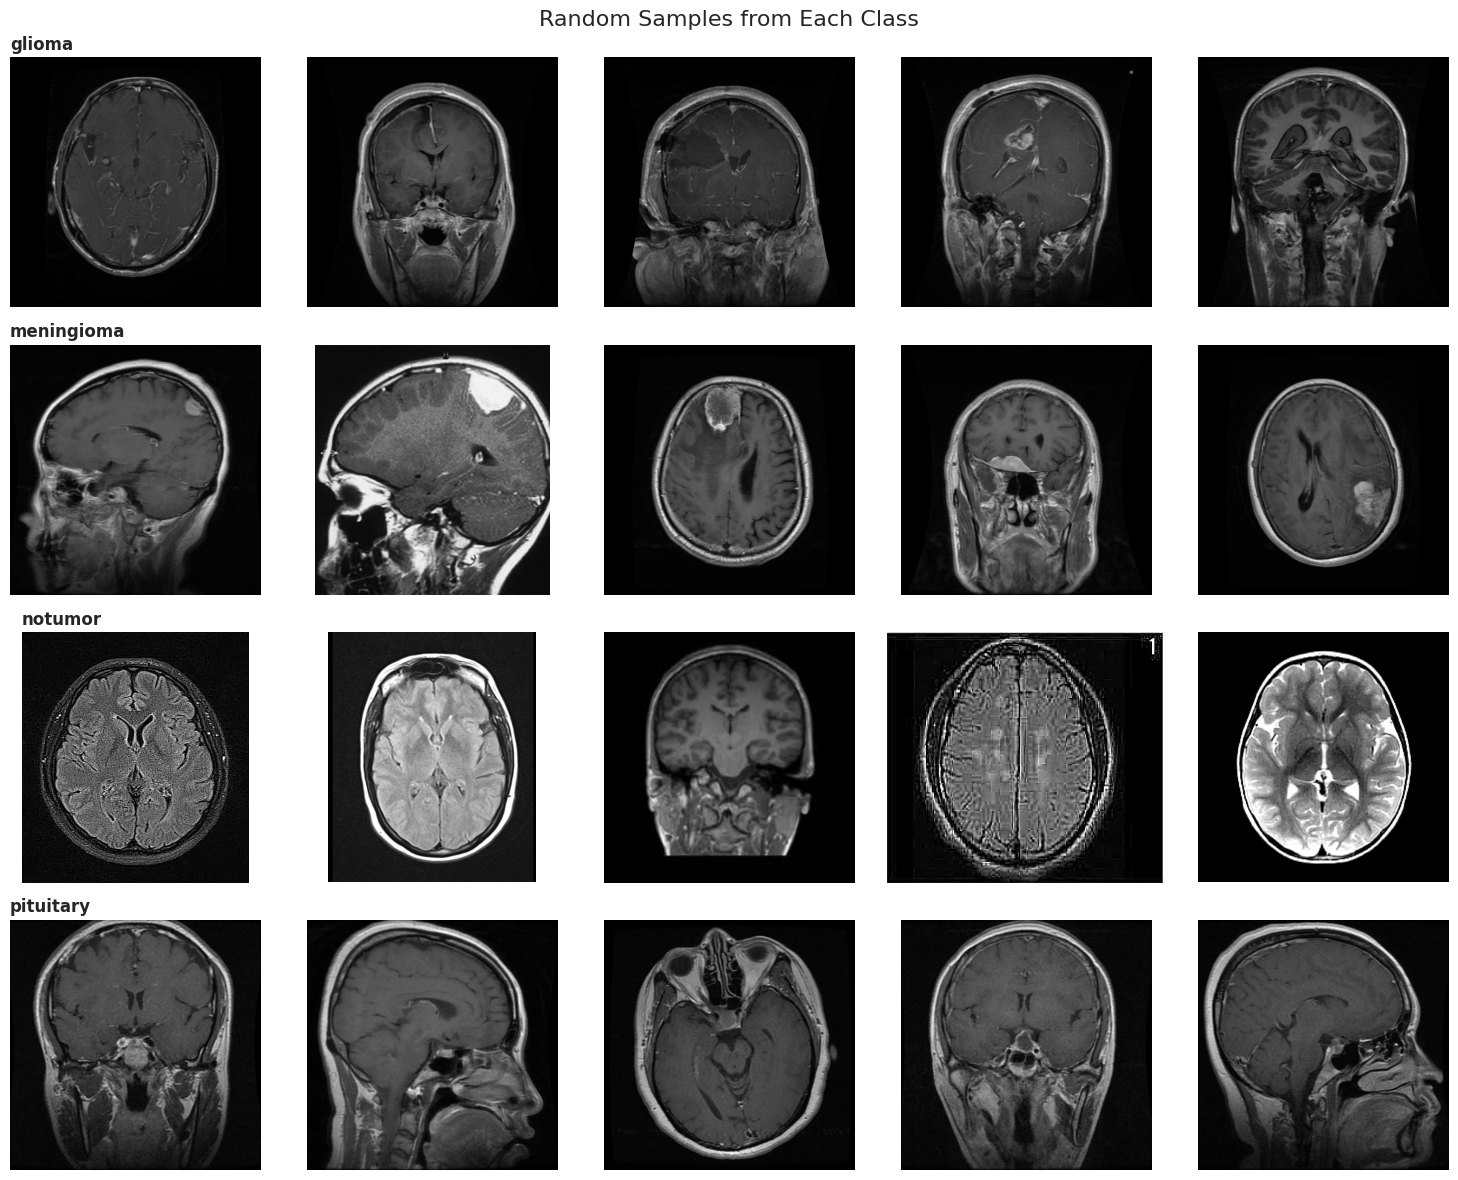

In [6]:
classes = sorted(df["label"].unique())
n_per_class = 5

fig, axes = plt.subplots(len(classes), n_per_class, figsize=(15, 3 * len(classes)))
for i, cls in enumerate(classes):
    paths = df[(df["label"] == cls) & (df["split"] == "Training")]["path"].tolist()
    chosen = random.sample(paths, n_per_class)
    for j, p in enumerate(chosen):
        img = Image.open(p)
        axes[i, j].imshow(img, cmap="gray")
        axes[i, j].axis("off")
        if j == 0:
            axes[i, j].set_title(cls, loc="left", fontsize=12, fontweight="bold")
plt.suptitle("Random Samples from Each Class", fontsize=16)
plt.tight_layout()
plt.show()

We analyze pixel values (0–255): mean, standard deviation and histogram. We also build a “mean image” per class. The mean and std are later used for normalization. A random sample is used to keep it fast.

Global mean (0-1 scale): 0.1816
Global std  (0-1 scale): 0.1954


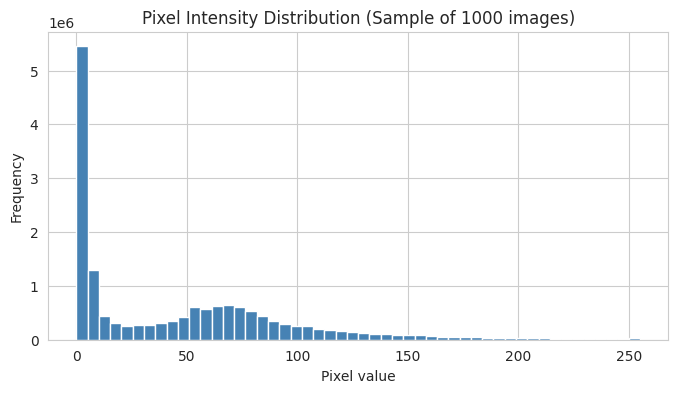

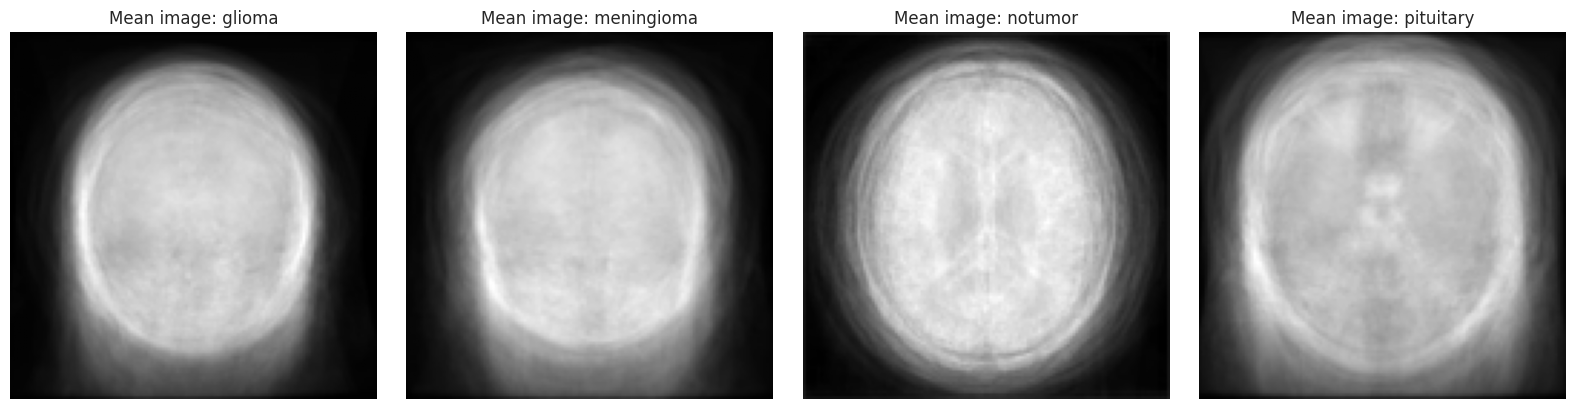

In [7]:
# Load a random sample of training images as grayscale, resized to 128x128
sample_df = df[df["split"] == "Training"].sample(1000, random_state=42)

def load_gray(path, size=(128, 128)):
    img = Image.open(path).convert("L").resize(size)
    return np.array(img, dtype=np.float32)

sample_arrays = np.stack([load_gray(p) for p in sample_df["path"]])

# Global statistics (scaled to 0-1, useful for normalization)
scaled = sample_arrays / 255.0
print("Global mean (0-1 scale):", round(scaled.mean(), 4))
print("Global std  (0-1 scale):", round(scaled.std(), 4))

# Pixel intensity histogram
plt.figure(figsize=(8, 4))
plt.hist(sample_arrays.ravel(), bins=50, color="steelblue")
plt.title("Pixel Intensity Distribution (Sample of 1000 images)")
plt.xlabel("Pixel value")
plt.ylabel("Frequency")
plt.show()

# Mean image for each class
fig, axes = plt.subplots(1, len(classes), figsize=(16, 4))
for ax, cls in zip(axes, classes):
    cls_paths = df[(df["label"] == cls) & (df["split"] == "Training")]["path"].sample(200, random_state=42)
    mean_img = np.mean([load_gray(p) for p in cls_paths], axis=0)
    ax.imshow(mean_img, cmap="gray")
    ax.set_title(f"Mean image: {cls}")
    ax.axis("off")
plt.tight_layout()
plt.show()

We check four things: (1) corrupted files, (2) duplicate images (via MD5 hash) and whether the same image appears in both Training and Testing (data leakage), (3) blurry images (low Laplacian variance means blurry), (4) very dark or very bright images. Wrong labels can only be caught visually, so inspecting samples as in Cell 6 is the best approach. This cell may take a few minutes.

Corrupted images: 0
Images involved in exact duplication: 340
Duplicates inside Training: 171
Images shared between Training and Testing: 0

Blur score summary:
 count     1500.000000
mean       984.997411
std       3774.833262
min          5.690517
25%         50.019203
50%         68.992709
75%        187.148977
max      48579.178509
Name: blur, dtype: float64

Brightness summary:
 count    1500.000000
mean       47.329312
std        18.161391
min        14.944813
25%        34.727283
50%        43.689911
75%        54.395861
max       126.733810
Name: brightness, dtype: float64


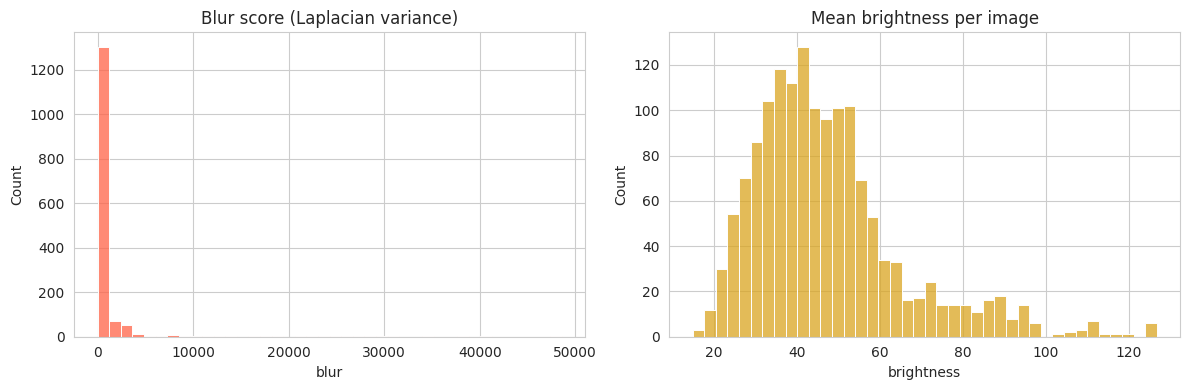

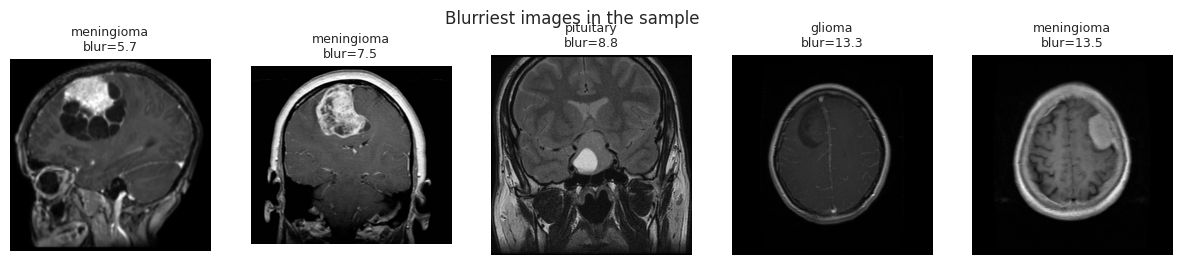

In [8]:
# 1) Corrupted file check
corrupted = []
for p in df["path"]:
    try:
        with Image.open(p) as im:
            im.verify()
    except Exception:
        corrupted.append(p)
print("Corrupted images:", len(corrupted))

# 2) Duplicate check using MD5 hash of file bytes
def file_hash(path):
    with open(path, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

df["hash"] = df["path"].apply(file_hash)
dup_mask = df.duplicated(subset="hash", keep=False)
print("Images involved in exact duplication:", dup_mask.sum())
print("Duplicates inside Training:", df[df["split"] == "Training"].duplicated(subset="hash").sum())

# Check leakage: same image present in both Training and Testing
train_hashes = set(df[df["split"] == "Training"]["hash"])
test_hashes = set(df[df["split"] == "Testing"]["hash"])
print("Images shared between Training and Testing:", len(train_hashes & test_hashes))

# 3) and 4) Blur and brightness check on a random sample
check_df = df.sample(1500, random_state=42).copy()
blur_scores, brightness = [], []
for p in check_df["path"]:
    gray = cv2.imread(p, cv2.IMREAD_GRAYSCALE)
    blur_scores.append(cv2.Laplacian(gray, cv2.CV_64F).var())
    brightness.append(gray.mean())
check_df["blur"] = blur_scores
check_df["brightness"] = brightness

print("\nBlur score summary:\n", check_df["blur"].describe())
print("\nBrightness summary:\n", check_df["brightness"].describe())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(check_df["blur"], bins=40, ax=axes[0], color="tomato")
axes[0].set_title("Blur score (Laplacian variance)")
sns.histplot(check_df["brightness"], bins=40, ax=axes[1], color="goldenrod")
axes[1].set_title("Mean brightness per image")
plt.tight_layout()
plt.show()

# Show the 5 blurriest images in the sample
worst = check_df.nsmallest(5, "blur")
fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for ax, (_, row) in zip(axes, worst.iterrows()):
    ax.imshow(Image.open(row["path"]), cmap="gray")
    ax.set_title(f"{row['label']}\nblur={row['blur']:.1f}", fontsize=9)
    ax.axis("off")
plt.suptitle("Blurriest images in the sample")
plt.show()

We gather all EDA findings in one place and decide: which size to resize to, which mean/std to use for normalization, which class weights are needed if imbalance exists, and whether to remove duplicate or corrupted files.

In [9]:
print("========== EDA SUMMARY ==========")
print("Total images           :", len(df))
print("Classes                :", classes)
print("Training / Testing     :", int((df["split"] == "Training").sum()), "/", int((df["split"] == "Testing").sum()))

# Most common image size -> candidate resize target (converted to plain Python ints)
common_size = tuple(int(v) for v in df.groupby(["width", "height"]).size().idxmax())
print("Most common size (W,H) :", common_size)
print("Unique image sizes     :", df.groupby(["width", "height"]).ngroups)

# Normalization values computed from the training sample
print("Normalization mean/std :", round(float(scaled.mean()), 4), "/", round(float(scaled.std()), 4))

# Class weights for the training set (inverse frequency, plain Python floats)
train_counts = df[df["split"] == "Training"]["label"].value_counts()
total = int(train_counts.sum())
class_weights = {cls: round(float(total / (len(train_counts) * cnt)), 3)
                 for cls, cnt in train_counts.items()}
print("Suggested class weights:", class_weights)

print("Corrupted files        :", len(corrupted))
print("Duplicate files        :", int(df.duplicated(subset="hash").sum()))

# Clean dataframe (corrupted files and exact duplicates removed)
clean_df = df[~df["path"].isin(corrupted)].drop_duplicates(subset="hash").reset_index(drop=True)
print("Images after cleaning  :", len(clean_df))

print("\nPlan:")
print(f"1. Resize all images to a fixed size such as 224x224 (most common original: {common_size}).")
print("2. Convert to 3 channels if using a pretrained RGB model, or keep 1 channel for a custom CNN.")
print("3. Normalize using the computed mean/std.")
print("4. Use class weights or augmentation if imbalance is noticeable.")
print("5. Keep Testing as the final test set; create a validation split from Training.")
print("6. Use final_df from Cell 10 (not clean_df) for the train/validation split.")

========== EDA SUMMARY ==========
Total images           : 7200
Classes                : ['glioma', 'meningioma', 'notumor', 'pituitary']
Training / Testing     : 5600 / 1600
Most common size (W,H) : (512, 512)
Unique image sizes     : 447
Normalization mean/std : 0.1816 / 0.1954
Suggested class weights: {'glioma': 1.0, 'meningioma': 1.0, 'notumor': 1.0, 'pituitary': 1.0}
Corrupted files        : 0
Duplicate files        : 187
Images after cleaning  : 7013

Plan:
1. Resize all images to a fixed size such as 224x224 (most common original: (512, 512)).
2. Convert to 3 channels if using a pretrained RGB model, or keep 1 channel for a custom CNN.
3. Normalize using the computed mean/std.
4. Use class weights or augmentation if imbalance is noticeable.
5. Keep Testing as the final test set; create a validation split from Training.
6. Use final_df from Cell 10 (not clean_df) for the train/validation split.


clean_df removes duplicates across Training and Testing together, so we do not control which split loses the image. This cell first shows where duplicates are located. Then it removes duplicates from Training only, keeping Testing untouched, and also drops any Training image that matches a Testing image (to prevent data leakage). Finally, it recomputes class weights for the cleaned Training set.

In [10]:
# Split the dataframe into Training and Testing parts
train_df = df[df["split"] == "Training"]
test_df = df[df["split"] == "Testing"]

# Where are the duplicates located?
print("Duplicates inside Training :", int(train_df.duplicated(subset="hash").sum()))
print("Duplicates inside Testing  :", int(test_df.duplicated(subset="hash").sum()))
print("Shared Training/Testing    :", len(set(train_df["hash"]) & set(test_df["hash"])))

# Clean Training: remove internal duplicates, then remove images that also exist in Testing
train_clean = train_df.drop_duplicates(subset="hash")
train_clean = train_clean[~train_clean["hash"].isin(set(test_df["hash"]))]

# Remove corrupted files (if any) from both parts
train_clean = train_clean[~train_clean["path"].isin(corrupted)]
test_final = test_df[~test_df["path"].isin(corrupted)]

# Keep Testing unchanged so the test set stays fixed
final_df = pd.concat([train_clean, test_final]).reset_index(drop=True)

print("\nTraining before/after :", len(train_df), "/", len(train_clean))
print("Testing (unchanged)   :", len(test_final))
print("Final total           :", len(final_df))

print("\nClass counts after cleaning (Training):")
print(train_clean["label"].value_counts())

# Recompute class weights on the cleaned Training set
clean_counts = train_clean["label"].value_counts()
clean_total = int(clean_counts.sum())
new_class_weights = {cls: round(float(clean_total / (len(clean_counts) * cnt)), 3)
                     for cls, cnt in clean_counts.items()}
print("\nUpdated class weights :", new_class_weights)

Duplicates inside Training : 171
Duplicates inside Testing  : 16
Shared Training/Testing    : 0

Training before/after : 5600 / 5429
Testing (unchanged)   : 1600
Final total           : 7029

Class counts after cleaning (Training):
label
glioma        1400
meningioma    1386
pituitary     1362
notumor       1281
Name: count, dtype: int64

Updated class weights : {'glioma': 0.969, 'meningioma': 0.979, 'pituitary': 0.997, 'notumor': 1.06}
